# Fashion-MNIST · Análisis exploratorio visual

Ejecuta las tres celdas de código en orden. Consulta la [metodología](../docs/metodologia.md). Los comentarios y cifras se calculan al ejecutar; las alertas no certifican calidad del modelo.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("fashion_mnist_classification")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from fashion_mnist_classification.alerts import configurar_notebook, mostrar_alertas
configurar_notebook()


# Clasificación visual de prendas: eda

El EDA usa solo **12,000 imágenes de entrenamiento**, de **28×28 píxeles y un canal**. Las clases tienen entre **1200 y 1200 ejemplos**; el **50.20%** de los píxeles vale cero. Los ejemplos y promedios permiten inspeccionar formas; no prueban separación predictiva ni representan fotos reales.


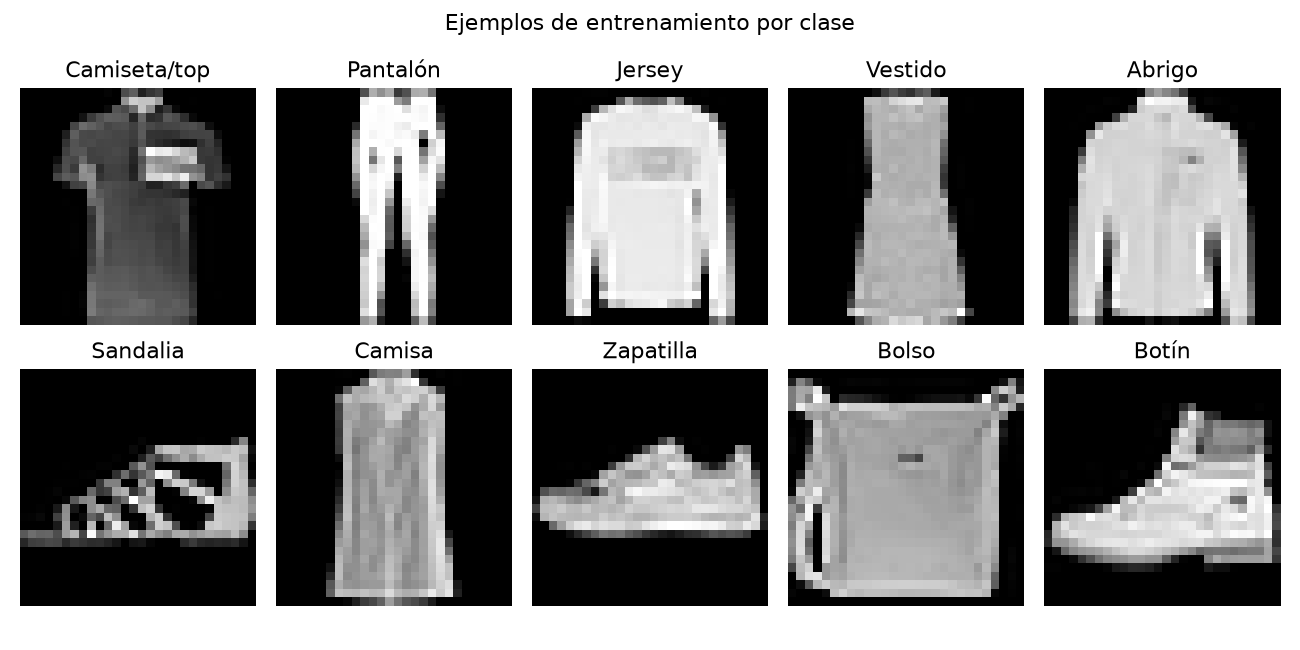

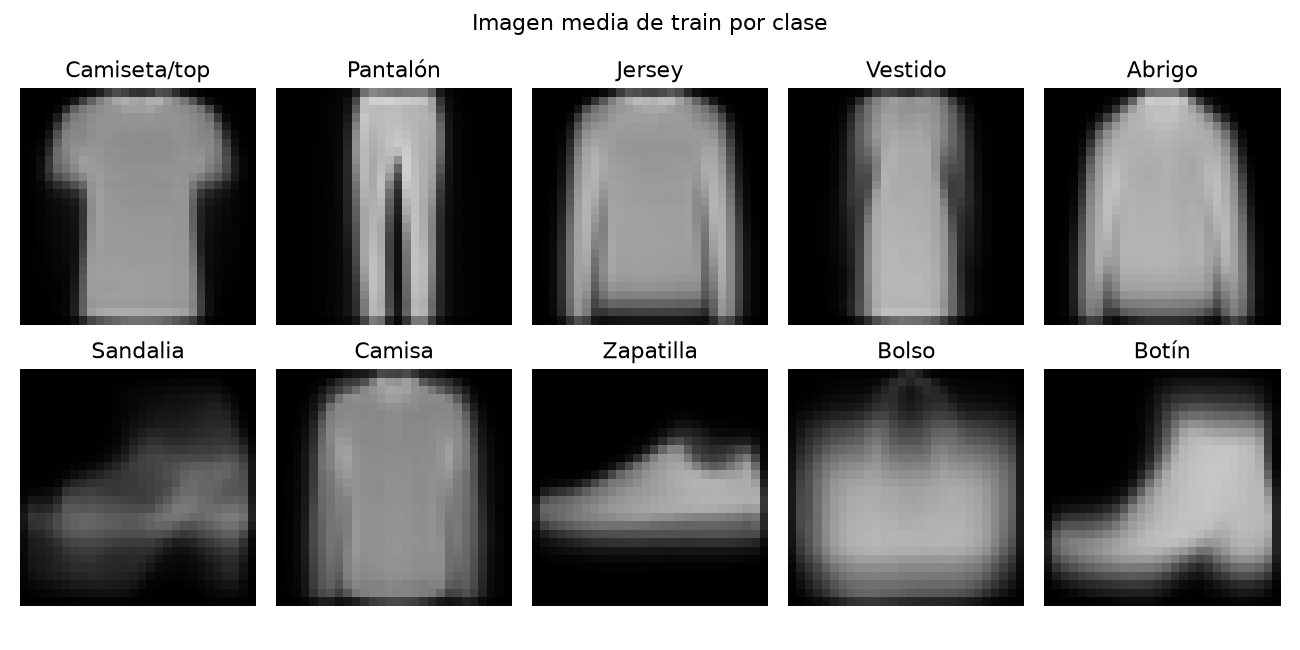

In [2]:
from fashion_mnist_classification.flow import run_stage
metrics, comment = run_stage(PROJECT_ROOT, "eda")
display(Markdown(comment))
from IPython.display import Image
display(Image(filename=str(PROJECT_ROOT/"reports/eda/eda.png")))
display(Image(filename=str(PROJECT_ROOT/"reports/eda/promedios_clase.png")))


## Alertas e informe

Revisa la descripción y acción sugerida de cada aviso.


In [3]:
mostrar_alertas(PROJECT_ROOT/"reports/alertas/02_analisis_exploratorio.json")
from fashion_mnist_classification.informe import generar_informe
informe = generar_informe(PROJECT_ROOT)
display(Markdown("[Informe integral](../reports/informe_final/informe_final.md)"))


[Informe integral](../reports/informe_final/informe_final.md)